# Lithium from oilfield produced water by solvent extraction

For chemical engineers who know Python and some IDAES, but not lithium or solvent extraction. *Run All* takes about
2 minutes. The notebook follows the paper it accompanies, in six questions:

| Part | Question | Short answer |
|---|---|---|
| 1 | Why lithium from produced water? | Batteries need lithium, and this waste water holds some, but with about 115 sodium ions for every lithium ion. |
| 2 | How does solvent extraction work, and how is it modeled? | Water and an oil-like liquid are mixed and settled; the model calculates how much lithium and sodium end up in each liquid at every stage, inside an IDAES flowsheet. |
| 3 | Which solvent extracts best? | On softened MS-2, three systems recover about 99.7 % or more in three stages; only D2EHDTPA/BuPhen leaves more lithium than sodium in the loaded organic. |
| 4 | What does the whole process cost? | From raw water to lithium carbonate, the operating cost alone needs about 21 times the assumed base price of 17,500 USD/t LCE on one water and 8 times on a richer one. |
| 5 | Which waters are strong leads? | Of 14 measured waters, four combinations: the three richest in lithium with D2EHDTPA/BuPhen (the third only just), and one low-calcium water with softened HBTA/TOPO. |
| 6 | What can these predictions tell you, and what can't they? | They are reproduced model predictions, not measurements on these waters. |

An optional appendix optimizes a design and lets you try your own.

## 1. Why lithium from produced water?

**Answer:** produced water is a waste stream that holds lithium, and solvent extraction can take it out without
evaporation ponds, if the much larger amount of sodium can be kept out of the product.

- **Demand.** Batteries use about 88 % of the world's lithium, and lithium use rose about 20 % in 2025 (USGS Mineral
  Commodity Summaries 2026).
- **Today's sources.** Hard-rock ores, and continental brines concentrated in open-air evaporation ponds that lose most
  of the brine water.
- **Produced water.** Oil and gas wells bring up large volumes of salty water, managed as a waste. Some, such as the
  Smackover water of southern Arkansas, holds tens to a few hundred mg/L of lithium.
- **The difficulty.** The water holds far more sodium, calcium and magnesium than lithium:
  - calcium and magnesium consume acidic extractants and precipitate with carbonate, so they are removed first
    (**softening**) or tolerated by the extractant;
  - sodium, about **115 ions per lithium ion** in the main water here, competes for the extractant and follows lithium
    toward the product.

### Terms used throughout

| Term | Meaning |
|---|---|
| MS-2, Mars Hill | USGS produced-water samples from the Smackover Formation, Arkansas (168 and 423 mg/L Li) |
| softening | removing calcium and magnesium by precipitating them with sodium hydroxide and soda ash (Na$_2$CO$_3$) |
| O/A | organic-to-aqueous volume ratio |
| raffinate, loaded organic | the water leaving the last extraction stage; the organic carrying the extracted metals |
| $E_{Li}$, $D_M$, $\beta$ | lithium recovery; distribution coefficient of metal M (organic over aqueous concentration); separation factor $D_{Li}/D_{Na}$ |
| LCE | lithium carbonate equivalent: 1 kg of lithium makes 5.32 kg of Li$_2$CO$_3$ |
| break-even price | the lithium carbonate price at which the product just pays the operating cost |
| margin | value of the lithium carbonate minus the operating cost, per m$^3$ of raw water |

## 2. How does solvent extraction work, and how is it modeled?

**Answer:** the brine is mixed with an oil-like organic liquid that holds an extractant, and the two liquids settle
apart. Lithium, and some sodium, move into the organic. The model calculates how much lithium and sodium end up in each
liquid at every stage, inside an IDAES flowsheet.

### 2.1 Import the tools

IDAES and PrOMMiS pieces, the stage property packages, and small helpers that take the model `m` and do one job each.

In [1]:
import lithium_tutorial_tools as tools
import lithium_produced_water_tools as pw
import lithium_solvent_comparison_tools as sc

from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

from prommis.lithium_extraction.process import (
    acid_recovery as chain,
    costing,
    strip_and_carbonation as downstream,
)
from prommis.lithium_extraction.extraction import stage
from prommis.lithium_extraction.extraction.stage import (
    ExtentReactions,
    MolarFlowParameters,
)

tools.versions()

,version
ePC-SAFT Engine,1.3.1
IDAES,2.13.0
PrOMMiS,1.1.0
Pyomo,6.10.1


### 2.2 How a countercurrent cascade works

- Mix the water (the **aqueous** phase) with an oil-like **organic** phase that holds an extractant; lithium moves into
  the organic; the two liquids settle apart. One mix-and-settle step is a **stage**.
- **Countercurrent:** water flows from stage 1 to stage $N$, fresh organic enters at stage $N$ and flows back, so the
  water meets the cleanest organic just before it leaves.
- Afterwards, a dilute acid **scrub** washes sodium off the loaded organic, a stronger acid **strip** returns the
  lithium to a small volume of water, and the organic is reused.

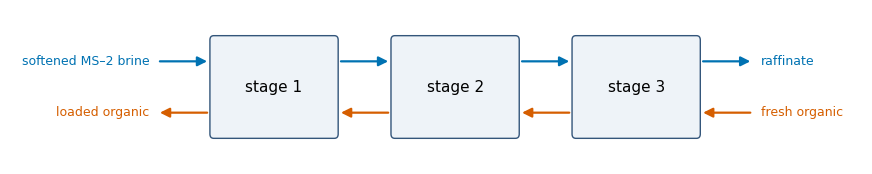

In [2]:
sc.draw_cascade()

**Why ePC-SAFT.** The brine is concentrated salt water (2.8 to 4.6 mol/L sodium in the feeds here), far from ideal, and
its acidity and sodium change from stage to stage. A fixed distribution coefficient cannot predict that. Electrolyte
PC-SAFT (**ePC-SAFT**), an equation of state for electrolyte solutions, gives the activity of every ion and molecule in
both liquids. Its equilibrium library, the **Engine**, solves each stage as a chemical and phase equilibrium.

The rest of this part builds the three-stage cascade above for the simplest system, **acid-form HBTA/TOPO** (HBTA,
benzoyltrifluoroacetone, the acidic extractant; TOPO, tri-*n*-octylphosphine oxide, a neutral co-extractant), at
25 °C and 1 atm.

### 2.3 The feed

MS-2 with calcium, magnesium, strontium and barium assumed already removed and no lithium lost. The same feed serves all
four systems in Part 3; a dash marks a species a system's model leaves out.

In [3]:
sc.feed_table()

,mol per L feed,mg/L,"model feed, HBTA/TOPO and DES (mol/L)","model feed, D2EHDTPA/BuPhen (mol/L)"
Li,0.0242,168,0.0242,0.0242
Na,2.79,"64,100",2.79,2.79
K,0.0588,"2,300",—,—
water,55.5,—,55.5,55.5
H,1.7e-06,0.00171,1.7e-06,—
Cl,2.87,"101,794",2.81,2.81
Mg,0,0,—,—
Ca,0,0,—,—
Sr,0,0,—,—
Ba,0,0,—,—


### 2.4 The chemistry

With HBTA written HA and TOPO written T, lithium and sodium enter the organic by releasing a proton:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}},
\qquad \mathrm{M = Li,\ Na}
$$

Reaction $r$ is at equilibrium when $\sum_{p,i} \nu_{r,pi} \ln a_{pi} = \ln K_r$, with activities $a$ from ePC-SAFT
and $K_r$ fitted to published data. The cell returns the Engine's chemistry record, the organic reference state and
the feed in mol/L.

In [4]:
chemistry, reference, brine = sc.acid_hbta_topo()
tools.species(chemistry)

{'aqueous species': ['water',
  'lithium-cation',
  'sodium-cation',
  'hydrogen-cation',
  'chloride-anion'],
 'organic species': ['diluent',
  'hbta',
  'topo',
  'LiA·T complex',
  'NaA·T complex']}

### 2.5 Build the flowsheet

Flows are mol/h at 1 L/h of feed, so every flow equals mol per litre of feed. Each cell adds one piece.

1. A steady-state flowsheet with one property package per liquid.

In [5]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)
m.fs.aqueous_properties = MolarFlowParameters(
    phase="aqueous", species=chemistry.supports[0]
)
m.fs.organic_properties = MolarFlowParameters(
    phase="organic", species=chemistry.supports[1]
)

2. Transfer extents: in stage $k$, $\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k$ with
   $\mathbf C\,\mathbf N = \mathbf 0$, so no extent creates or destroys lithium, sodium, exchangeable H, BTA or TOPO.

In [6]:
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistry))

3. One PrOMMiS `SolventExtraction` unit with three stages: water forward, organic backward. `m.fs.boundary[s]` is the
   feed of species $s$ and `m.fs.stage[k].outlet[s]` the amount leaving stage $k$.

In [7]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=3,
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={
        "property_package": m.fs.aqueous_properties,
        "flow_direction": FlowDirection.forward,
    },
    organic_stream={
        "property_package": m.fs.organic_properties,
        "flow_direction": FlowDirection.backward,
    },
)
tools.label_streams(m)
degrees_of_freedom(m)

25

4. Equilibrium in every stage: the Engine returns the outlet amounts from the inlet amounts as a Pyomo
   `ExternalFunction` with exact first and second derivatives.

In [8]:
tools.add_stage_equilibrium(m, [chemistry] * 3)
degrees_of_freedom(m)

10

5. Fix the feed.

In [9]:
for species, amount in brine.items():
    m.fs.boundary[species].fix(amount)
degrees_of_freedom(m)

5

6. Fix the paper's acid-form design: O/A = 3 and 0.3 mol/L each of HBTA and TOPO, both at their upper bounds. The model
   is now square.

In [10]:
start, design = sc.design("acid_A")
sc.add_design(m, design, reference)
assert degrees_of_freedom(m) == 0

### 2.6 Initialize and solve

`sc.initialize` solves the stages one at a time with the Engine for a starting point; IPOPT then solves all three
together with exact second derivatives. `tools.solve` stops with an error unless the optimality conditions are met.

In [11]:
sc.initialize(m, brine)
tools.solve(m, "acid_hbta_topo")

IPOPT: optimal; largest optimality-condition residual 3e-14


### 2.7 Result: acid release limits the acid form

Recovery is $E_{Li} = 1 - n_{Li,\,raffinate} / n_{Li,\,feed}$. Amounts leaving each stage, mol per litre of feed:

In [12]:
recovery = 1 - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"]
print(f"Lithium recovery: {100 * recovery:.2f} %")
tools.stage_profile(
    m,
    [
        "lithium-cation",
        "sodium-cation",
        "hydrogen-cation",
        "LiA·T complex",
        "NaA·T complex",
    ],
)

Lithium recovery: 39.71 %


stage,1,2,3
lithium-cation,0.02,0.0174,0.0146
sodium-cation,2.78,2.77,2.76
hydrogen-cation,0.0147,0.0239,0.0384
LiA·T complex,0.00961,0.00536,0.00286
NaA·T complex,0.0288,0.0183,0.0116


- Only about **40 %** of the lithium is recovered.
- Every Li⁺ extracted releases an H⁺, and the acid building up in the water holds extraction back.

## 3. Which solvent extracts best?

**Answer:** the three systems that release sodium instead of acid, or take up chloride, recover nearly all the lithium
in three stages. Only **D2EHDTPA/BuPhen** leaves more lithium than sodium in the loaded organic.

| System | How it takes up lithium |
|---|---|
| Acid-form HBTA/TOPO | trades a proton for Li⁺ (Part 2) |
| Sodium-saponified HBTA/TOPO | HBTA pre-reacted with NaOH, so it trades Na⁺ for Li⁺ instead of releasing acid |
| D2EHDTPA/BuPhen | a sodium-form dithiophosphate, bis(2-ethylhexyl)dithiophosphoric acid, trades Na⁺ for Li⁺; BuPhen (2,9-dibutyl-1,10-phenanthroline) binds the lithium |
| TBAC:DA/TOPO deep eutectic solvent (DES) | tetrabutylammonium chloride and decanoic acid with TOPO; takes up each metal ion with a chloride ion |

Each system runs at its own three-stage design for maximum lithium recovery, from the paper. Most optima sit on a design
bound:

In [13]:
sc.designs()

value
system                      design variable                                         
Acid HBTA/TOPO              O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.3 (upper bound)
                            r_Na, sodium-form fraction of HBTA                     0
Sodium-saponified HBTA/TOPO O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.4 (upper bound)
                            r_Na, sodium-form fraction of HBTA                 0.992
D2EHDTPA/BuPhen             O/A                                                 1.82
                            B, BuPhen (mol/L organic)              1.0 (upper bound)
                            S, sodium-form sites per mol feed Li   1.5 (upper bound)
TBAC:DA/TOPO DES            ammonia nitrogen (mol per L feed)                0.00512
                            TOPO mass fraction of the organic                  0.325

`sc.solve_all` builds and solves all four systems with the same stage structure. A design is kept only if IPOPT
converged, each stage re-solved on its own by the Engine matches the flowsheet, and every conserved total balances. The
first line confirms the hand-built model of Part 2 matches the study's own builder.

In [14]:
solved, status = sc.solve_all()
print(
    f"Largest outlet difference, hand-built against the study builder: {sc.largest_outlet_difference(m, solved):.1e} mol/L"
)
status

Largest outlet difference, hand-built against the study builder: 0.0e+00 mol/L


,solved,largest balance error (mol/L),largest stage re-solve difference (mol/L)
system,,,
Acid HBTA/TOPO,True,1.02e-14,1.42e-14
Sodium-saponified HBTA/TOPO,True,2.22e-16,2.13e-14
D2EHDTPA/BuPhen,True,2.52e-16,1.42e-14
TBAC:DA/TOPO DES,True,2.01e-14,7.82e-14


$E_{Li}$ is the lithium recovery of the whole three-stage cascade. $\beta$ and $x_{Na,org}$ (sodium's share of the lithium
plus sodium in the loaded organic) are for stage 1, where the water enters. $\Delta n_{Na,org}$ is the net sodium moved
into the organic (mol/m$^3$ of feed, negative when the saponified organic releases sodium), and the last row the lithium
left in the raffinate:

In [15]:
sc.headline(solved)

,Acid HBTA/TOPO,Sodium-saponified HBTA/TOPO,D2EHDTPA/BuPhen,TBAC:DA/TOPO DES
$E_{Li}$,0.397,> 0.999,0.997,$\approx 1$
$\beta = D_{Li}/D_{Na}$,46.4,163,753,370
"$x_{Na,org}$",0.75,0.979,0.336,0.9
"$\Delta n_{Na,org}$ (mol/m$^3$)",28.8,-88.3,-24.1,218
"$n_{Li,aq,N}$ (mol/L)",0.0146,8.63e-08,8.27e-05,$< 10^{-9}$


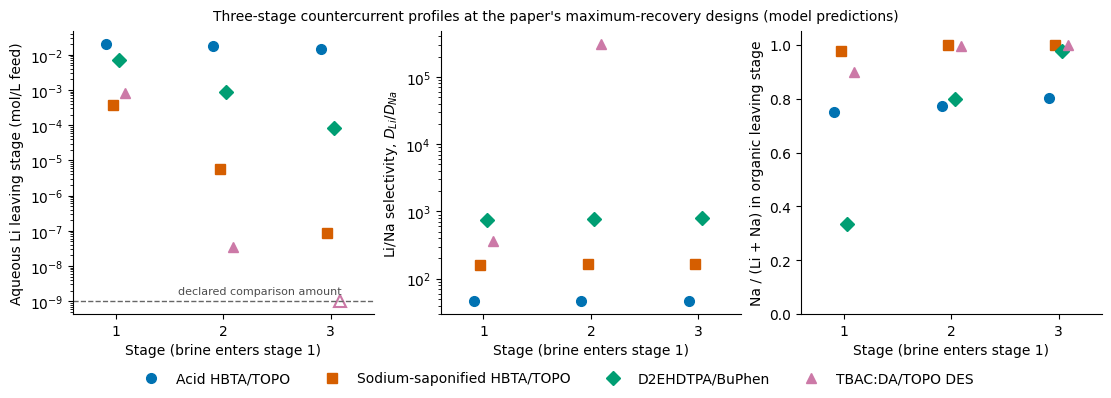

In [16]:
sc.plot_profiles(sc.profiles(solved))

- **Acid-form HBTA/TOPO is the outlier:** 39.7 % recovery against about 99.7 % or more for the other three.
- **High recovery is not a lithium-rich organic.** With about 115 Na per Li in the feed, sodium is **98 %** of the
  lithium plus sodium in the loaded organic for saponified HBTA/TOPO and **90 %** for the DES, but **34 %** for D2EHDTPA/BuPhen.
- That sodium follows lithium downstream, so the choice of process is decided after extraction: Part 4.

## 4. What does the whole process cost?

**Answer:** for saponified HBTA/TOPO on MS-2, **69 %** of the raw water's lithium reaches lithium carbonate at
**1,968 USD per kg of lithium**, so the product pays its operating cost only at about **21 times** the assumed base price of 17,500 USD/t LCE. Mars
Hill, with 2.5 times the lithium, needs about **8 times**.

![Block flow diagram of the process](lithium_produced_water_process_block_flow_diagram.png)

*Block flow diagram from the paper (Figure 1). This part follows the upper lane:*

1. **Softening:** NaOH and soda ash precipitate magnesium and calcium as sludge; HCl restores the pH.
2. **Extraction:** five countercurrent stages of HBTA/TOPO, 70 % of the HBTA saponified.
3. **Scrub:** dilute HCl removes most of the sodium from the loaded organic.
4. **Strip:** stronger HCl moves the lithium into the strip liquor; most unused acid is recovered; the organic is
   re-saponified and reused.
5. **Carbonation:** soda ash precipitates lithium carbonate; most of the mother liquor is recycled.

**Basis:** 1 m$^3$/h of raw water at base-case prices, each water at its cheapest design from the paper (O/A = 1,
at least 95 % lithium extraction). The operating cost counts reagents, sludge disposal and replacing 1 % of the organic
per pass (HBTA at 100 USD/kg); energy, capital and labor are left out.

### 4.1 Waters and softening

Calcium and magnesium per kilogram of lithium set most of the softening cost. `pw.soften` reads the stored Reaktoro
equilibrium doses (down to 5 mg/L magnesium and 5 mg/L calcium).

In [17]:
pw.waters()

,Li (mg/L),Na (mg/L),Ca (mg/L),Mg (mg/L),Cl (mg/L),(Ca+Mg)/Li (kg/kg),selected stages,HBTA (mol/L organic),O/A,saponified fraction
MS-2,168,"64,100","36,900","3,310","174,000",239,5,0.1,1,0.7
Mars Hill,423,"72,500","29,300","2,243","176,679",74.6,5,0.114,1,0.7


In [18]:
softened = {site: pw.soften(site) for site in pw.WATERS}
pw.softening_table(softened)

,NaOH (kg/m3 raw),soda ash (kg/m3 raw),"HCl, 31% (kg/m3 raw)",wet sludge (kg/m3 raw),softened water (L per L raw),Ca+Mg left (mg/L),Li kept in softened water (%)
MS-2,11.7,99.3,1.92,343,1,5.45,92.7
Mars Hill,7.4,80,0.24,274,0.997,6.07,94.2


### 4.2 Build and solve the extraction stages

- The stage build of Part 2, reused for five stages by `tools.extraction_flowsheet`.
- Saponified HBTA trades sodium for lithium:
  $\mathrm{Li^+_{(aq)} + NaA{\cdot}T_{(org)} \rightleftharpoons LiA{\cdot}T_{(org)} + Na^+_{(aq)}}$; HBTA also
  dissolves slightly into the water.
- Inside extraction, flows are per litre of softened water; $v$ (L softened per L raw water) converts to the raw-water
  basis used downstream.

In [19]:
site = "MS2"
water = softened[site][pw.CASE]
v = water["feed_l"]  # L softened water per L raw water
start = pw.starting_profile(site, softened)
chemistries = pw.stage_chemistries(site, start)
print(
    f"{len(chemistries)} stages, {len(set(map(id, chemistries)))} Engine record(s); v = {v:.4f}"
)

5 stages, 1 Engine record(s); v = 1.0036


In [20]:
acid_form = m  # the acid-form cascade of Part 2, optimized in the appendix
m = tools.extraction_flowsheet(chemistries, v)
pw.add_extractant_inventory(m, site)

The softened water and the fresh organic (0.10 mol/L HBTA with equal TOPO, 70 % saponified), per litre of softened
water. The design is then fixed and the model must be square.

In [21]:
pw.feed_extraction(m, site, water)

,softened water,fresh organic
mmol per L of softened water,,
water,"55,508",0
lithium-cation,22.4,0
sodium-cation,"4,584",0
hydrogen-cation,0.00169,0
hydroxide-anion,0,0
bta-anion,0,0
chloride-anion,"4,607",0
hbta,0,30
topo,0,30


In [22]:
pw.add_design(m, site, water)
assert degrees_of_freedom(m) == 0

Solve the extraction alone first, then re-solve every stage on its own with the Engine and require agreement:

In [23]:
stage.initialize(m, pw.stage_amounts(start))
tools.solve(m, "MS2_extraction")
extraction = pw.check_extraction(m)
print(
    f"Lithium extraction: {100 * value(m.fs.design.li_extraction):.2f} % of the softened water's lithium"
)

IPOPT: optimal; largest optimality-condition residual 4e-14


Lithium extraction: 99.53 % of the softened water's lithium


### 4.3 Add the downstream units

1. Pick the first admissible downstream alternative (how the scrub acid is set; which interval of the measured
   lithium carbonate solubility applies) and its closed-form balances, used to start the units.

In [24]:
candidate, _ = pw.downstream_alternatives(m, site, softened)
assumptions, accounts = pw.downstream_accounts(m, site, candidate)

2. Scrub and strip: one-stage PrOMMiS `SolventExtraction` units, each moving a set fraction $f_M$ of each metal from the
   organic to the acid, $n_{M,aq}^{out} = f_M\, n_{M,org}^{in}$:
   - scrub, 1 mol/L HCl: $f_{Na} = 0.90$ and $f_{Li} = 0.10$ (Zhang et al. 2018);
   - strip, 2.5 mol/L HCl: $f_{Li} = 0.95$ (Zhang et al. 2017) and $f_{Na} = 1$ (assumed).

In [25]:
pw.add_scrub_and_strip(m, assumptions, candidate, accounts)

3. Acid recovery (90 % of the unused strip acid), NaOH neutralization, and concentration to 1 mol Li per kg of water.

In [26]:
downstream.liquor_properties(m.fs)
concentrate = chain.aqueous(
    m.fs, assumptions, m.fs.design.organic_to_aqueous_ratio * v, m.fs.strip.metals["Li"]
)

4. Organic reuse: 1 % lost per pass and topped up; 70 % of the HBTA re-saponified.

In [27]:
chain.organic(m.fs, m, assumptions, v, "hbta")

5. Carbonation at 70 °C in the PrOMMiS `Precipitator`, with 90 % of the mother liquor recycled; dissolved lithium follows
   measured Li$_2$CO$_3$ solubility in NaCl solutions (Ge et al. 2025). This call also connects every unit.

In [28]:
downstream.connect(m.fs, concentrate, assumptions, candidate, accounts)

6. Initialize the downstream units in sequence, with the extraction held at its solution.

In [29]:
pw.initialize_downstream(m, assumptions, accounts)

7. Costing: an IDAES `FlowsheetCostingBlock` prices each consumed item,

$$
\dot C = \sum_j p_j\, \dot m_j \ \ [\mathrm{USD/h}], \qquad
C_{op} = \frac{\dot C}{Q_{raw}} \ \ [\mathrm{USD/m^3}], \qquad
C_{Li} = \frac{\dot C}{\dot m_{Li}} \ \ [\mathrm{USD/kg\ Li}], \qquad
P_{LCE}^{\,\text{break-even}} = \frac{C_{Li}}{5.32} \ \ [\mathrm{USD/kg\ LCE}],
$$

with $Q_{raw}$ = 1 m$^3$/h of raw water and $\dot m_{Li}$ the lithium in the product (kg/h).

In [30]:
flows, lithium_kg_h = pw.priced_flows(m, accounts)
costing.attach(m.fs, flows, lithium_kg_h)
degrees_of_freedom(m)

0

### 4.4 Solve the whole process

One IPOPT solve covers every unit and the costing. `pw.whole_process_result` then re-solves every stage with the Engine,
recomputes balances and costs, and requires every process limit to hold.

In [31]:
tools.solve(m, "MS2_whole_process")
result = pw.whole_process_result(m, site, softened)

IPOPT: optimal; largest optimality-condition residual 2e-14


### 4.5 Results for MS-2

Where the lithium goes, in grams per m$^3$ of raw water:

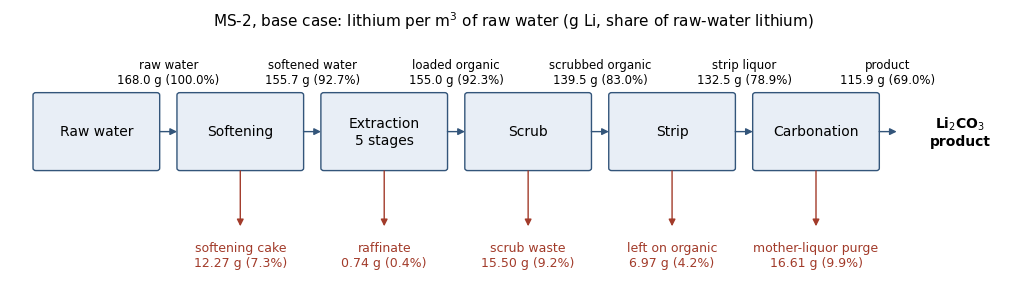

Lithium balance residual (raw water minus product and losses): 6.1e-16 mol per L of raw water


In [32]:
pw.lithium_diagram(result, site)

What the operating cost is made of:

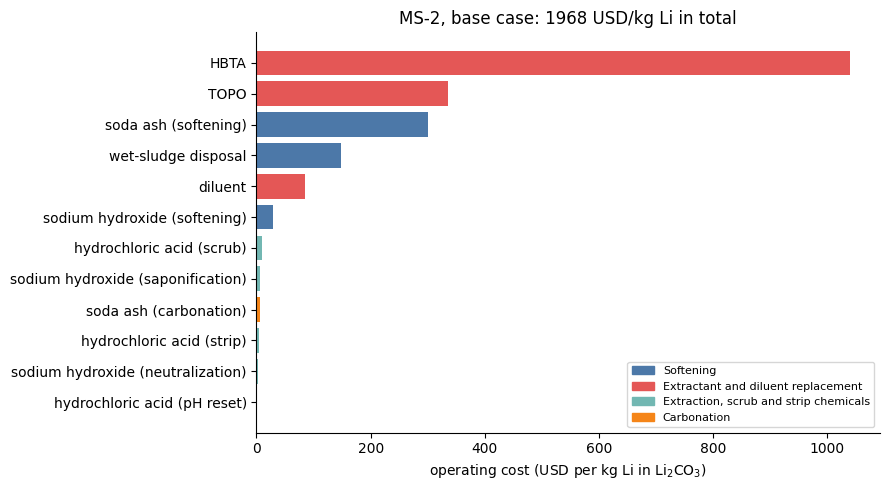

,USD/m3 raw water,USD/kg Li
step,,
Softening,55.4,478
Extractant and diluent replacement,169,"1,460"
"Extraction, scrub and strip chemicals",2.8,24
Carbonation,0.7,6.1


In [33]:
costs = pw.costs(m)
pw.plot_costs(costs, site, result["cost_usd_kg_li"])
costs.groupby("step", sort=False)[["USD/m3 raw water", "USD/kg Li"]].sum().round(1)

- **Extraction is not the problem:** extraction takes up 99.5 % of the lithium in softened MS-2; the product keeps 69 %
  of the raw-water lithium; the largest losses are the mother-liquor purge and the scrub waste.
- **HBTA replacement is the largest cost:** HBTA dissolves into the raffinate on every pass on top of the 1 % loss.

### 4.6 MS-2 against Mars Hill

`pw.run_water` builds and solves Mars Hill with the same units at its own design. *Extraction* is the share of the
softened water's lithium taken up; *recovery* the share of the raw water's lithium in the product.

In [34]:
results = {site: result}
_, results["MarsHill"] = pw.run_water("MarsHill", softened)
pw.summary(results)

,MS-2,Mars Hill
extraction stages,5,5
HBTA (mol/L organic),0.1,0.114
Li extraction (%),99.5,95
Li recovery to Li2CO3 (%),69,64.3
Li2CO3 product (kg per m3 raw),0.617,1.45
operating cost (USD/kg Li),"1,968",750
operating cost (USD/m3 raw water),228,204
break-even price (USD/t LCE),"369,748","140,947"
break-even / base price,21.1,8.05


- Mars Hill has **2.5 times** the lithium and less than a third of the calcium and magnesium per kilogram of lithium:
  **750** against **1,968 USD per kg of lithium**.
- Neither water reaches operating break-even on this basis.
- The screen in Part 5 leaves extractant purchase out of the margin, so there Mars Hill HBTA/TOPO comes much closer.

## 5. Which waters are strong leads?

**Answer:** four combinations are Strong leads. **D2EHDTPA/BuPhen**, which needs no softening, is one on the three waters
with at least 252 mg/L lithium. Softened **HBTA/TOPO** is one only on Westmoreland, the water with the least calcium and
magnesium per lithium (a Marcellus water from Pennsylvania). BR-2 (252 mg/L) with D2EHDTPA/BuPhen sits on the break-even
line: its base margin of +0.041 USD/m$^3$ vanishes at a BuPhen price of 571 USD/kg, just above the 569 USD/kg central
estimate, so it is not a firm lead.

The paper applies one design rule, one price table and one solvent-loss rule to 14 measured waters, read here from its
result files (not solved). Each rated combination gets a margin at base and optimistic prices and a label:

- **Strong lead:** positive base margin;
- **Promising:** positive optimistic margin, base margin at least −0.5 USD/m$^3$;
- **Borderline:** optimistic margin at least −0.5 USD/m$^3$;
- **Poor:** below that.

- Energy, capital and labor are left out of every margin.
- The HBTA/TOPO margin also leaves out extractant purchase (TOPO has no published price).
- D2EHDTPA/BuPhen uses the paper's Figiel-based calibration, and its margin includes lost ligand at prices estimated
  from reagent costs.
- Three cells have no margin. On USGS 115557, the water with the least lithium, no D2EHDTPA/BuPhen design lies inside
  the design ranges, and every HBTA/TOPO design leaves carbonation outside the measured solubility range. On USGS 45101,
  the HBTA/TOPO optimization did not converge.

Numbered waters are sample identifiers in the USGS Produced Waters Geochemical Database.

In [35]:
pw.paper_headline()

Assumed lithium carbonate price: 17,500 (base) to 20,900 (optimistic) USD/t LCE


water                     \
             Li (mg/L) (Ca+Mg)/Li (kg/kg)   
USGS 45903         440                110   
Mars Hill          423               74.6   
BR-2               252                171   
USGS 1005          208                129   
USGS 1570          202               77.6   
MS-2               168                239   
Westmoreland       117               27.3   
DM-5               105                349   
USGS 115047        100                114   
USGS 1568           93                 50   
USGS 20492        90.1                290   
USGS 45101          61                700   
USGS 103144         56               72.6   
USGS 115557         30               36.7   

             saponified HBTA/TOPO, softened water                             \
                             base margin (USD/m3) optimistic margin (USD/m3)   
USGS 45903                                    -46                      -6.11   
Mars Hill                                   -21.4                       5.63   
BR-2                                        -46.9                      -15.5   
USGS 1005                                   -42.5                        -14   
USGS 1570                                   -15.8                      0.141   
MS-2                                        -47.1                      -19.4   
Westmoreland                                0.203                       3.75   
DM-5                                        -45.8                      -20.9   
USGS 115047                                   -15                      -3.96   
USGS 1568                                   -3.26                       1.52   
USGS 20492                                  -35.3                      -15.2   
USGS 45101                                                                     
USGS 103144                                 -3.15                      0.537   
USGS 115557                                                                    

                          D2EHDTPA/BuPhen, raw water  \
                    label       base margin (USD/m3)   
USGS 45903           Poor                       12.4   
Mars Hill      Borderline                       11.7   
BR-2                 Poor                      0.041   
USGS 1005            Poor                      -2.21   
USGS 1570      Borderline                      -1.72   
MS-2                 Poor                      -6.42   
Westmoreland  Strong lead                       -6.1   
DM-5                 Poor                      -13.5   
USGS 115047          Poor                      -12.5   
USGS 1568      Borderline                        -10   
USGS 20492           Poor                      -17.7   
USGS 45101      not rated                      -21.9   
USGS 103144    Borderline                        -22   
USGS 115557     not rated                              

                                                      
             optimistic margin (USD/m3)        label  
USGS 45903                           26  Strong lead  
Mars Hill                          24.8  Strong lead  
BR-2                                 10  Strong lead  
USGS 1005                          6.65   Borderline  
USGS 1570                          6.67   Borderline  
MS-2                                2.3   Borderline  
Westmoreland                      0.246   Borderline  
DM-5                              -4.62         Poor  
USGS 115047                       -4.18         Poor  
USGS 1568                         -2.99         Poor  
USGS 20492                        -7.49         Poor  
USGS 45101                        -11.9         Poor  
USGS 103144                       -8.56         Poor  
USGS 115557                                not rated

- **Lithium content decides D2EHDTPA/BuPhen:** margins fall with lithium, and lost BuPhen is its largest cost.
- **Softening decides HBTA/TOPO:** it is positive at base prices only where calcium and magnesium are low.
- A strong lead marks a combination worth further research, not a profitable process.

## 6. What can these predictions tell you, and what can't they?

**Answer:** they rank solvents and waters on one consistent basis and show what drives cost. They are model
predictions, not measurements, and leave out energy, capital and labor.

- **Predictions, numerically verified.** Each chemistry is fitted to published laboratory data on other solutions; no
  extraction was measured on these waters.
- **Accuracy differs by system.** On published data withheld from the fits, saponified HBTA/TOPO predicts the lithium
  distribution coefficient within a factor of two at 10 of 11 points (average absolute relative deviation, AARD, 23 %);
  D2EHDTPA/BuPhen predicts 10 of 16 Li/Mg and Li/Ca selectivities within a factor of two (AARD 92 %), with most misses
  in calcium, and no withheld data test its Li/Na selectivity.
- **HBTA loss.** The saponified model underpredicts the one measured HBTA loss by 6–30 %, and HBTA replacement is the
  largest cost in Part 4.
- **Assumed inputs.** Scrub and strip fractions, softening doses, extractant prices and solvent losses are screening
  assumptions, not quotes or measurements.
- **Lower bounds.** Without energy, capital and labor, break-even prices are lower bounds, and a positive margin does
  not establish profitability.

### Reproduction check

Every number solved above is compared with the paper's stored results: for the four systems, each results-row quantity
and stage outlet; for the worked example, each cost, fraction, stage outlet, stream and softening amount. A point below
the red line is within tolerance; a failure stops the cell with an error.

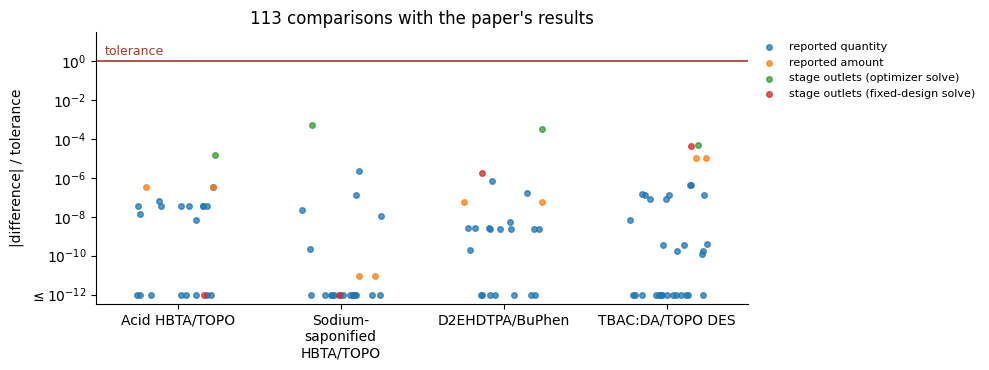

,comparisons,largest difference / tolerance,all within tolerance
Acid HBTA/TOPO,25,1.4e-05,✓
Sodium-saponified HBTA/TOPO,25,5.1e-04,✓
D2EHDTPA/BuPhen,25,3.1e-04,✓
TBAC:DA/TOPO DES,38,5.0e-05,✓


In [36]:
stage_summary, comparisons = sc.check_against_paper(solved)
stage_summary

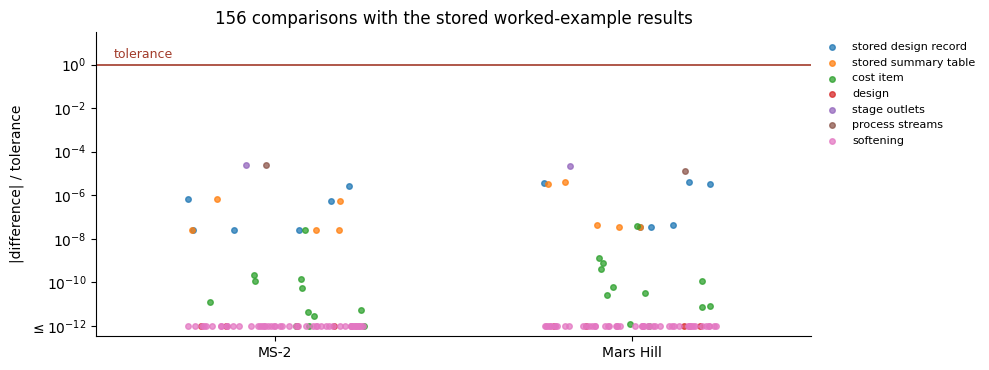

,comparisons,largest difference / tolerance,all within tolerance
MS-2,78,2.4e-05,✓
Mars Hill,78,2.1e-05,✓


In [37]:
process_summary, checks = pw.check_against_paper(results, softened)
process_summary

## Appendix: optimize and explore (optional)

### A.1 Optimize the acid-form design

Because the Engine is just one more equation to IDAES, the same flowsheet can be optimized. Start the acid-form cascade
of Part 2 at a weak design, O/A = 1 and $c$ = 0.1 mol/L:

In [38]:
m = acid_form
design = m.fs.design
design.organic_to_aqueous_ratio.fix(1.0)
design.extractant_mol_l.fix(0.1)
sc.initialize(m, brine)
tools.solve(m, "acid_hbta_topo_start")
starting = {
    "O/A": 1.0,
    "c (mol/L organic)": 0.1,
    "$E_{Li}$": 1
    - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"],
}
starting

IPOPT: optimal; largest optimality-condition residual 3e-14


{'O/A': 1.0, 'c (mol/L organic)': 0.1, '$E_{Li}$': 0.08627474365531485}

Now free both inside the paper's bounds ($0.5 \le \mathrm{O/A} \le 3$, $0.05 \le c \le 0.30$ mol/L) and minimize the
lithium left in the raffinate:

In [39]:
from pyomo.environ import Objective

design.organic_to_aqueous_ratio.unfix()
design.extractant_mol_l.unfix()
m.feasibility.deactivate()
m.raffinate_lithium = Objective(expr=m.fs.stage[3].outlet["lithium-cation"])
print("Degrees of freedom:", degrees_of_freedom(m))
tools.solve(m, "acid_hbta_topo_optimize")

Degrees of freedom: 2


IPOPT: optimal; largest optimality-condition residual 9e-13


In [40]:
sc.optimum_table(m, brine, starting)

,starting design,optimized here,paper's optimum,relative difference
O/A,1,3,3,2.23e-10
c (mol/L organic),0.1,0.3,0.3,1.14e-10
$E_{Li}$,0.0863,0.397,0.397,1.85e-10


- Recovery rises from 8.6 % to 39.7 %.
- Both variables go to their upper bounds, matching the paper's optimum within $3 \times 10^{-10}$ relative difference.

### A.2 Try other stage designs

Pick a solvent system, the number of stages and its design, then run the cell below the widgets (a few seconds each).
Widgets work only in a running notebook (see the setup page beside this notebook).

In [41]:
designs = sc.DesignOptions()
designs

DesignOptions(children=(Dropdown(description='solvent system', layout=Layout(width='560px'), options=(('Acid H…

In [42]:
sc.run_design(designs)

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146


Every design solved so far, recovery against the sodium share of the loaded organic. Two designs start the comparison:
the acid form at O/A = 2 and D2EHDTPA/BuPhen with one stage.

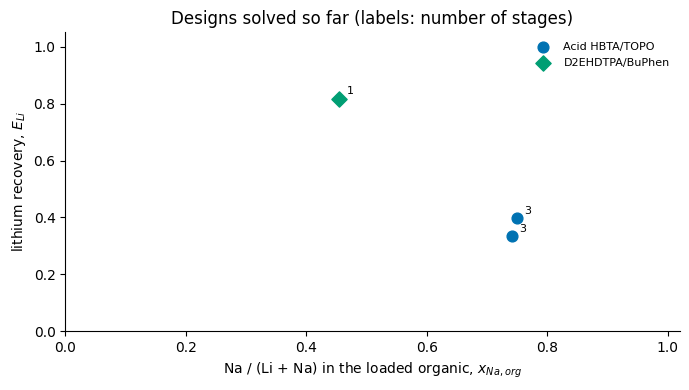

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146
1,Acid HBTA/TOPO,3,"O/A = 2, c = 0.3 (upper bound)",0.334,46.4,0.742,23.3,0.0161
2,D2EHDTPA/BuPhen,1,"O/A = 1.82, B = 1.0 (upper bound), S = 1.5 (up...",0.817,760,0.455,-19.8,0.00442


In [43]:
designs.system.label, designs.stages.value = "Acid HBTA/TOPO", 3
designs.sliders.children[0].value = 2.0
sc.run_design(designs)
designs.system.label, designs.stages.value = "D2EHDTPA/BuPhen", 1
sc.run_design(designs)
sc.compare_designs()